# Notebook 02 — Exploratory Data Analysis

This notebook explores the cleaned June 2026 DB1C airline ticket sample produced in Notebook 01.

Notebook 01 identified eight initial candidate predictors based on data quality, redundancy, dimensionality, and interpretability. This notebook examines the distributions and descriptive relationships of these variables before regression modelling begins.

The analysis is descriptive only. No formal regression-based variable selection, regression diagnostics, or model refinement is performed in this notebook.

## 1. Import & Load Prepared Data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_FILE = PROCESSED_DATA_DIR / "db1c_ticket_prepared_202606.parquet"

df = pd.read_parquet(DATA_FILE)

print(f"Rows:    {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows:    90,086
Columns: 16


,ItinID,TotalAmount,TotalDistance,Coupons,RoundTrip,OnLine,PurchaseWindowGroup,RpCarrier,ItinGeoType,OriginState,Origin,OriginCityMarketID,TaxAmount,AmountExclTax,RpYear,RpMonth
0,20260618618554,398.40,1069.0,1,0,1,21AP,DL,2,FL,FLL,32467,42.12,356.28,2026,6
1,20260610813469,686.81,3180.0,2,1,1,2290,WN,2,IN,IND,32337,76.57,610.24,2026,6
2,20260617427446,644.10,3114.0,3,0,0,2290,DL,2,CA,LGB,32575,78.52,565.58,2026,6
3,2026068607173,306.55,780.0,2,1,1,2290,WN,2,CA,ONT,32575,47.95,258.60,2026,6
4,2026065403481,466.44,3488.0,4,1,1,21AP,F9,2,CA,SFO,32457,70.88,395.56,2026,6


#### Interpretation

The prepared dataset loads successfully with 90,086 observations and 16 variables.

The sample matches the final output from Notebook 01, so all subsequent exploratory analysis will be based on the same cleaned and reproducible dataset.

### 1.1 Candidate Predictor Set

The eight candidate predictors carried forward from Notebook 01 are:

| Dimension | Candidate variable |
|---|---|
| Travel distance | `TotalDistance` |
| Itinerary complexity | `Coupons` |
| Trip structure | `RoundTrip` |
| Carrier structure | `OnLine` |
| Purchase timing | `PurchaseWindowGroup` |
| Carrier identity | `RpCarrier` |
| Itinerary geography | `ItinGeoType` |
| Origin geography | `OriginState` |

`Origin` and `OriginCityMarketID` remain available for descriptive or sensitivity analysis but are not included in the initial broad model because their high cardinality would require several hundred additional indicator variables.

The purpose of the exploratory analysis is therefore to assess whether any of the eight pre-screened candidate variables appears clearly unsuitable or redundant before formal regression modelling.

## 2. Overall Fare Distribution

### 2.1 Summary Statistics

In [3]:
fare_summary = df["TotalAmount"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(fare_summary.to_frame("TotalAmount"))

,TotalAmount
count,90086.000000
mean,460.007031
std,354.023420
min,1.000000
1%,57.000000
5%,109.900000
10%,150.400000
25%,242.200000
50%,388.400000
75%,580.300000


In [4]:
fare_summary.to_frame("TotalAmount").to_csv(
    OUTPUT_DIR / "02_fare_summary.csv"
)

### 2.2 Fare Distribution

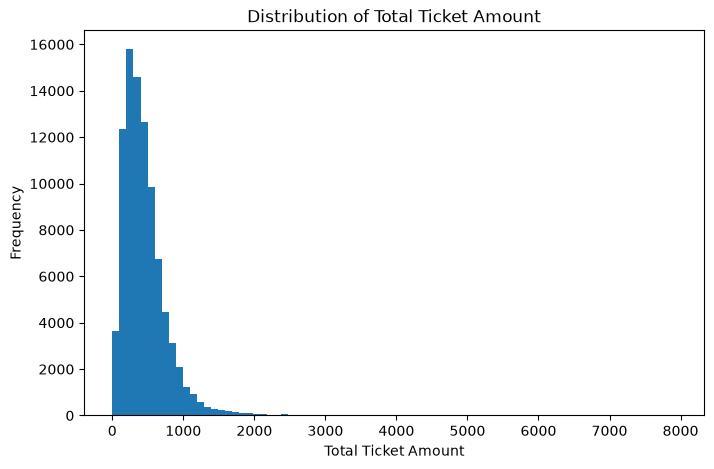

In [5]:
plt.figure(figsize=(8, 5))
plt.hist(
    df["TotalAmount"],
    bins=80
)

plt.xlabel("Total Ticket Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Total Ticket Amount")

plt.show()

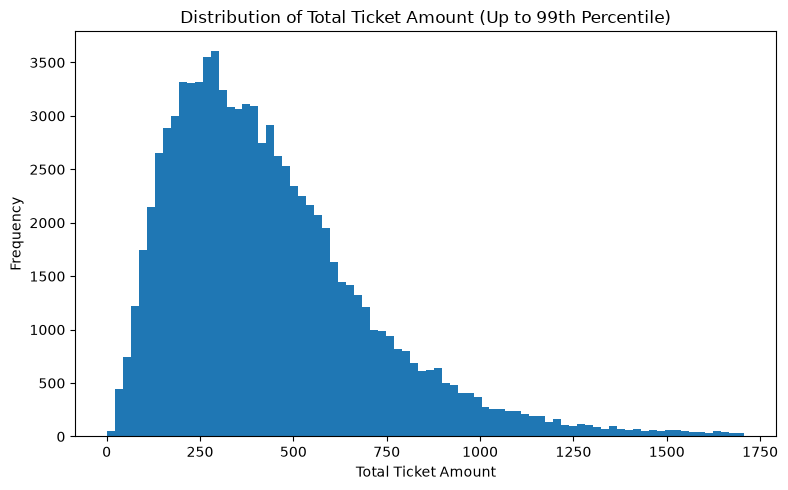

99th percentile fare: 1708.05


In [6]:
fare_p99 = df["TotalAmount"].quantile(0.99)

plt.figure(figsize=(8, 5))

plt.hist(
    df.loc[
        df["TotalAmount"] <= fare_p99,
        "TotalAmount"
    ],
    bins=80
)

plt.xlabel("Total Ticket Amount")
plt.ylabel("Frequency")
plt.title("Distribution of Total Ticket Amount (Up to 99th Percentile)")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "02_fare_distribution_p99.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"99th percentile fare: {fare_p99:.2f}")

#### Interpretation

`TotalAmount` shows a clear right-skewed distribution.

The median ticket amount is 388.40, compared with a higher mean of 460.01, reflecting the influence of relatively expensive tickets in the upper tail.

Most observations are concentrated in the lower-to-middle fare range:

- 50% of tickets cost 388.40 or less;
- 75% cost 580.30 or less;
- 90% cost 820.40 or less;
- 95% cost 1,008.75 or less.

The upper tail is relatively long. The 99th percentile is approximately 1,708, while the maximum observed fare is 7,935.82.

The histogram restricted to the 99th percentile confirms that the main body of the fare distribution is unimodal but positively skewed rather than symmetric.

No high-fare observations are removed at this stage. Whether the upper tail creates influential observations or affects the suitability of a linear model will be assessed later using formal regression diagnostics.

## 3. Numerical Predictor Exploration

### 3.1 Total Distance

In [7]:
distance_summary = df["TotalDistance"].describe(
    percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(distance_summary.to_frame("TotalDistance"))

,TotalDistance
count,90086.000000
mean,1924.575051
std,1384.999135
min,11.000000
1%,200.000000
5%,404.000000
10%,583.000000
25%,946.000000
50%,1600.000000
75%,2465.000000


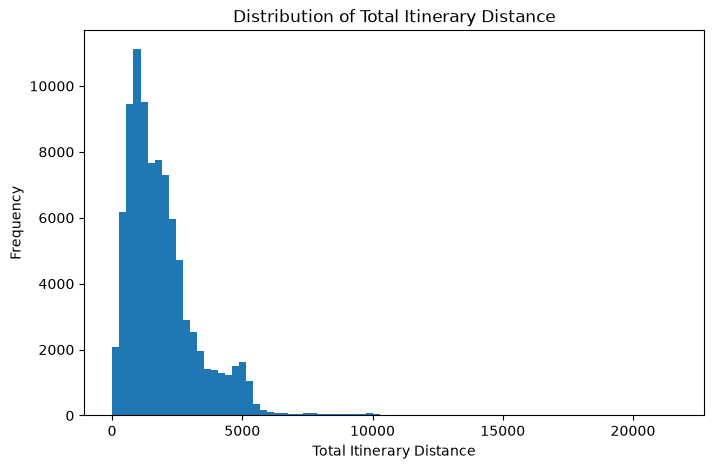

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["TotalDistance"],
    bins=80
)

plt.xlabel("Total Itinerary Distance")
plt.ylabel("Frequency")
plt.title("Distribution of Total Itinerary Distance")

plt.show()

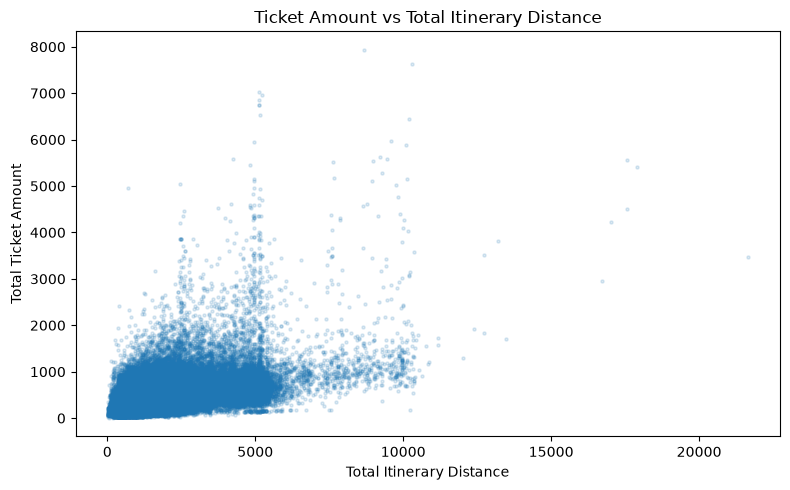

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["TotalDistance"],
    df["TotalAmount"],
    s=5,
    alpha=0.15
)

plt.xlabel("Total Itinerary Distance")
plt.ylabel("Total Ticket Amount")
plt.title("Ticket Amount vs Total Itinerary Distance")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "02_fare_vs_distance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
distance_fare_corr = df[
    ["TotalDistance", "TotalAmount"]
].corr().iloc[0, 1]

print(
    f"Correlation between TotalDistance and TotalAmount: "
    f"{distance_fare_corr:.3f}"
)

Correlation between TotalDistance and TotalAmount: 0.474


#### Interpretation

`TotalDistance` is also positively skewed. The median itinerary distance is 1,600 miles, while the mean is higher at approximately 1,925 miles. Most itineraries are below 5,000 miles, although a small number extend substantially further.

There is a clear positive relationship between itinerary distance and ticket amount. The Pearson correlation between `TotalDistance` and `TotalAmount` is approximately:

$$
r = 0.474
$$

This indicates a moderate positive linear association: longer itineraries generally tend to have higher ticket amounts.

The scatterplot also shows substantial dispersion around this relationship. Tickets with similar itinerary distances can have considerably different prices, suggesting that distance alone cannot explain fare variation and that other itinerary, carrier, purchase, and geographic characteristics are likely relevant.

The vertical spread in fares also appears to vary across distance levels. This is noted descriptively here but will be assessed formally through regression residual diagnostics in a later notebook.

No unusual long-distance observations are removed at this exploratory stage.

### 3.2 Number of Coupons

In [11]:
coupon_summary = (
    df.groupby("Coupons")
    .agg(
        observations=("TotalAmount", "size"),
        mean_fare=("TotalAmount", "mean"),
        median_fare=("TotalAmount", "median")
    )
    .reset_index()
)

coupon_summary["share_percent"] = (
    coupon_summary["observations"] / len(df) * 100
)

display(coupon_summary.round(2))

,Coupons,observations,mean_fare,median_fare,share_percent
0,1,28271,284.10,242.28,31.38
1,2,47051,487.56,428.80,52.23
2,3,3010,612.23,549.05,3.34
3,4,10748,711.62,625.83,11.93
4,5,739,885.37,750.50,0.82
5,6,243,1160.29,966.49,0.27
6,7,17,1362.39,1105.59,0.02
7,8,3,2810.60,3262.21,0.00
8,9,2,2025.57,2025.57,0.00
9,10,2,2514.26,2514.26,0.00


In [12]:
coupon_summary.to_csv(
    OUTPUT_DIR / "02_coupon_summary.csv",
    index=False
)

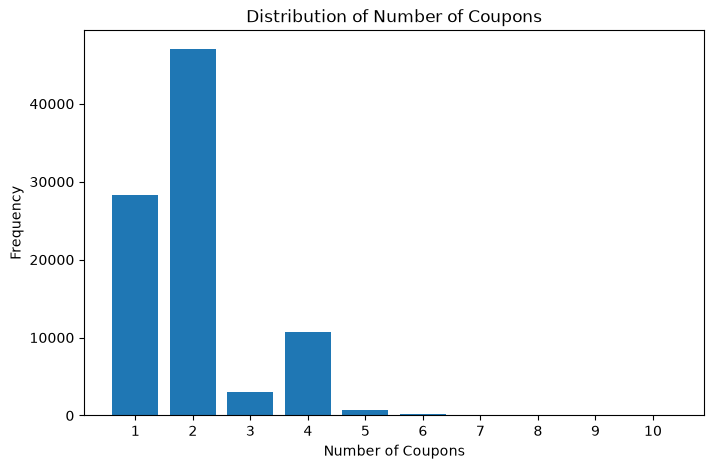

In [13]:
coupon_counts = df["Coupons"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    coupon_counts.index,
    coupon_counts.values
)

plt.xlabel("Number of Coupons")
plt.ylabel("Frequency")
plt.title("Distribution of Number of Coupons")
plt.xticks(coupon_counts.index)

plt.show()

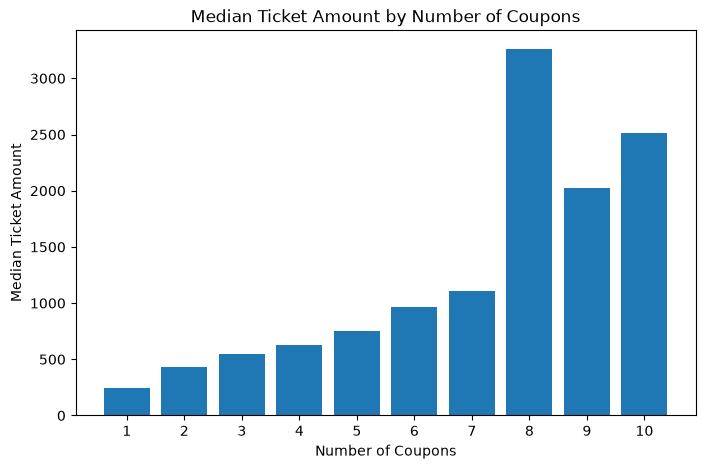

In [14]:
coupon_median_fare = (
    df.groupby("Coupons")["TotalAmount"]
    .median()
)

plt.figure(figsize=(8, 5))

plt.bar(
    coupon_median_fare.index,
    coupon_median_fare.values
)

plt.xlabel("Number of Coupons")
plt.ylabel("Median Ticket Amount")
plt.title("Median Ticket Amount by Number of Coupons")
plt.xticks(coupon_median_fare.index)

plt.show()

#### Interpretation

`Coupons` is highly concentrated at low values.

- 31.38% of observations contain 1 coupon;
- 52.23% contain 2 coupons;
- 11.93% contain 4 coupons;
- all coupon counts above 6 are extremely rare.

For the well-populated categories, ticket amount generally increases with the number of coupons. Median fare rises from approximately 242 for one-coupon itineraries to about 429 for two coupons, 549 for three coupons, 626 for four coupons, and 750 for five coupons.

This suggests that more complex itineraries tend to be associated with higher ticket amounts.

However, the apparent jumps for 8–10 coupons should not be interpreted as a reliable pattern because those categories contain only two or three observations each. Their mean and median fares are therefore highly unstable.

The relationship also need not be assumed to be perfectly linear. `Coupons` will be retained as a candidate predictor, while its appropriate functional treatment can be considered later during model construction.

## 4. Binary and Low-Cardinality Categorical Variables

### 4.1 Round-Trip Status

In [15]:
roundtrip_summary = (
    df.groupby("RoundTrip")
    .agg(
        observations=("TotalAmount", "size"),
        mean_fare=("TotalAmount", "mean"),
        median_fare=("TotalAmount", "median")
    )
    .reset_index()
)

roundtrip_summary["share_percent"] = (
    roundtrip_summary["observations"] / len(df) * 100
)

display(roundtrip_summary.round(2))

,RoundTrip,observations,mean_fare,median_fare,share_percent
0,0,40579,318.43,268.40,45.04
1,1,49507,576.05,510.38,54.96


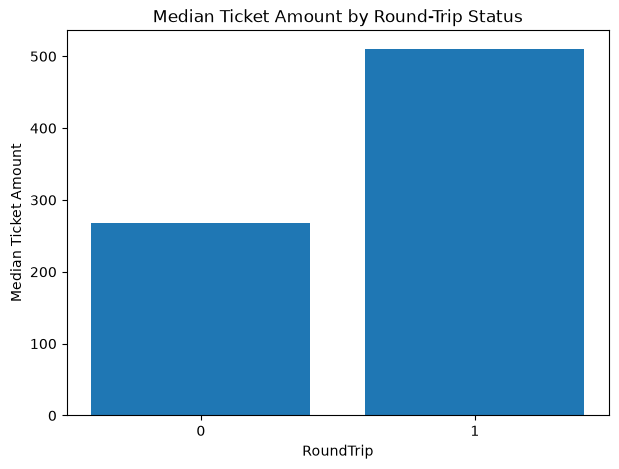

In [16]:
plt.figure(figsize=(7, 5))

plt.bar(
    roundtrip_summary["RoundTrip"].astype(str),
    roundtrip_summary["median_fare"]
)

plt.xlabel("RoundTrip")
plt.ylabel("Median Ticket Amount")
plt.title("Median Ticket Amount by Round-Trip Status")

plt.show()

#### Interpretation

Round-trip tickets are associated with substantially higher ticket amounts than one-way tickets in the cleaned sample.

- One-way itineraries (`RoundTrip = 0`) have a median fare of approximately 268.40.
- Round-trip itineraries (`RoundTrip = 1`) have a median fare of approximately 510.38.

The mean fares show the same pattern, with round-trip tickets averaging about 576 compared with 318 for one-way tickets.

The sample is also reasonably balanced across the two groups, with 45.04% one-way and 54.96% round-trip observations. This provides sufficient variation for `RoundTrip` to be retained as a categorical predictor.

This difference is descriptive rather than causal. Part of the higher round-trip fare may also reflect longer total travel distance or more complex itineraries, which will be controlled for later in the multiple-regression model.

### 4.2 OnLine Indicator

In [17]:
online_summary = (
    df.groupby("OnLine")
    .agg(
        observations=("TotalAmount", "size"),
        mean_fare=("TotalAmount", "mean"),
        median_fare=("TotalAmount", "median")
    )
    .reset_index()
)

online_summary["share_percent"] = (
    online_summary["observations"] / len(df) * 100
)

display(online_summary.round(2))

,OnLine,observations,mean_fare,median_fare,share_percent
0,0,11770,636.53,549.76,13.07
1,1,78316,433.48,365.80,86.93


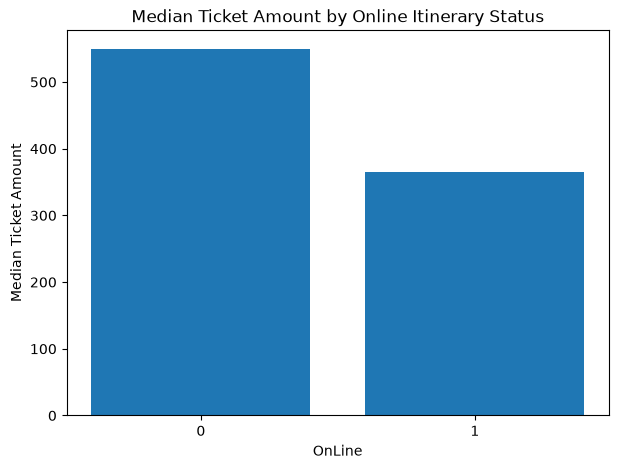

In [18]:
plt.figure(figsize=(7, 5))

plt.bar(
    online_summary["OnLine"].astype(str),
    online_summary["median_fare"]
)

plt.xlabel("OnLine")
plt.ylabel("Median Ticket Amount")
plt.title("Median Ticket Amount by Online Itinerary Status")

plt.show()

#### Interpretation

`OnLine` is highly concentrated in category 1, which represents 86.93% of the sample, while category 0 accounts for 13.07%.

Despite the imbalance, both groups contain substantial numbers of observations.

Tickets with `OnLine = 0` have noticeably higher fares:

- median fare of approximately 549.76 for `OnLine = 0`;
- median fare of approximately 365.80 for `OnLine = 1`.

The mean fares show the same pattern, at approximately 636.53 and 433.48 respectively.

This suggests that itinerary carrier structure may be associated with meaningful fare differences. However, the comparison is purely descriptive and may partly reflect differences in distance, itinerary complexity, carrier mix, or other characteristics.

`OnLine` will therefore remain as a candidate categorical predictor for the multiple-regression model.

### 4.3 Purchase Window Group

In [19]:
purchase_summary = (
    df.groupby("PurchaseWindowGroup")
    .agg(
        observations=("TotalAmount", "size"),
        mean_fare=("TotalAmount", "mean"),
        median_fare=("TotalAmount", "median")
    )
    .reset_index()
)

purchase_summary["share_percent"] = (
    purchase_summary["observations"] / len(df) * 100
)

display(purchase_summary.round(2))

,PurchaseWindowGroup,observations,mean_fare,median_fare,share_percent
0,21AP,41540,496.19,425.86,46.11
1,2290,38515,420.07,355.50,42.75
2,91UP,10031,463.50,386.40,11.13


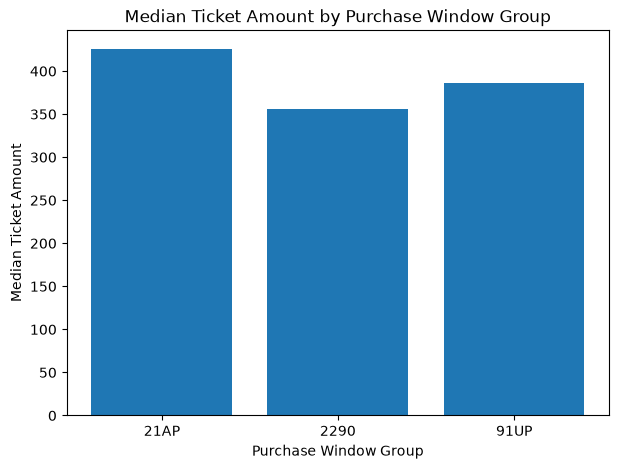

In [20]:
plt.figure(figsize=(7, 5))

plt.bar(
    purchase_summary["PurchaseWindowGroup"],
    purchase_summary["median_fare"]
)

plt.xlabel("Purchase Window Group")
plt.ylabel("Median Ticket Amount")
plt.title("Median Ticket Amount by Purchase Window Group")

plt.show()

#### Interpretation

Ticket amounts differ across the three `PurchaseWindowGroup` categories.

Median fares are approximately:

- 425.86 for `21AP`;
- 355.50 for `2290`;
- 386.40 for `91UP`.

The same general ordering is observed for mean fares, although the differences are not monotonic across the three coded groups.

All three categories are reasonably represented in the sample:

- `21AP`: 46.11%;
- `2290`: 42.75%;
- `91UP`: 11.13%.

The descriptive differences suggest that purchase timing may contain useful information for explaining fare variation. `PurchaseWindowGroup` will therefore be retained as a categorical candidate predictor.

The codes are treated as category labels at this stage. Their precise economic interpretation will be based on the official BTS definitions rather than inferred from the labels alone.

### 4.4 Itinerary Geographic Type

In [21]:
geotype_summary = (
    df.groupby("ItinGeoType")
    .agg(
        observations=("TotalAmount", "size"),
        mean_fare=("TotalAmount", "mean"),
        median_fare=("TotalAmount", "median")
    )
    .reset_index()
)

geotype_summary["share_percent"] = (
    geotype_summary["observations"] / len(df) * 100
)

display(geotype_summary.round(2))

,ItinGeoType,observations,mean_fare,median_fare,share_percent
0,1,7090,590.01,450.32,7.87
1,2,82996,448.90,384.81,92.13


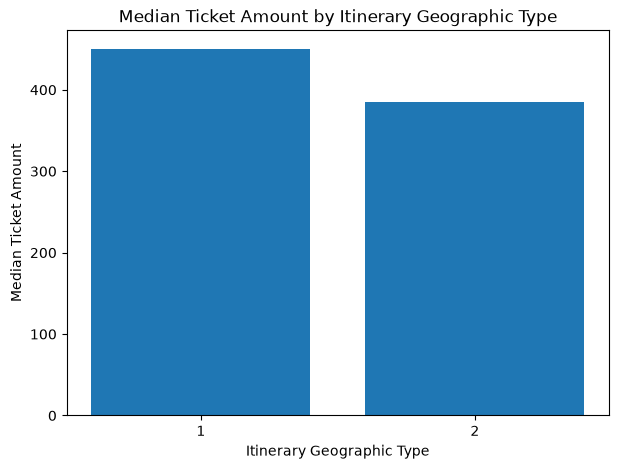

In [22]:
plt.figure(figsize=(7, 5))

plt.bar(
    geotype_summary["ItinGeoType"].astype(str),
    geotype_summary["median_fare"]
)

plt.xlabel("Itinerary Geographic Type")
plt.ylabel("Median Ticket Amount")
plt.title("Median Ticket Amount by Itinerary Geographic Type")

plt.show()

#### Interpretation

`ItinGeoType` is highly concentrated in category 2, which accounts for 92.13% of the sample, while category 1 represents 7.87%.

Category 1 is associated with higher ticket amounts:

- median fare of approximately 450.32 for `ItinGeoType = 1`;
- median fare of approximately 384.81 for `ItinGeoType = 2`.

The mean fares show the same pattern, at approximately 590.01 and 448.90 respectively.

Although the distribution is imbalanced, both categories contain enough observations for meaningful comparison. `ItinGeoType` will therefore remain as a candidate categorical predictor.

The precise economic interpretation of categories 1 and 2 should be based on the official BTS variable definition rather than inferred from the numerical codes alone.

In [23]:
roundtrip_export = roundtrip_summary.copy()
roundtrip_export.insert(0, "Variable", "RoundTrip")
roundtrip_export = roundtrip_export.rename(
    columns={"RoundTrip": "Category"}
)

online_export = online_summary.copy()
online_export.insert(0, "Variable", "OnLine")
online_export = online_export.rename(
    columns={"OnLine": "Category"}
)

purchase_export = purchase_summary.copy()
purchase_export.insert(0, "Variable", "PurchaseWindowGroup")
purchase_export = purchase_export.rename(
    columns={"PurchaseWindowGroup": "Category"}
)

geotype_export = geotype_summary.copy()
geotype_export.insert(0, "Variable", "ItinGeoType")
geotype_export = geotype_export.rename(
    columns={"ItinGeoType": "Category"}
)

categorical_summary = pd.concat(
    [
        roundtrip_export,
        online_export,
        purchase_export,
        geotype_export
    ],
    ignore_index=True
)

categorical_summary.to_csv(
    OUTPUT_DIR / "02_categorical_summary.csv",
    index=False
)

display(categorical_summary.round(2))

,Variable,Category,observations,mean_fare,median_fare,share_percent
0,RoundTrip,0,40579,318.43,268.40,45.04
1,RoundTrip,1,49507,576.05,510.38,54.96
2,OnLine,0,11770,636.53,549.76,13.07
3,OnLine,1,78316,433.48,365.80,86.93
4,PurchaseWindowGroup,21AP,41540,496.19,425.86,46.11
5,PurchaseWindowGroup,2290,38515,420.07,355.50,42.75
6,PurchaseWindowGroup,91UP,10031,463.50,386.40,11.13
7,ItinGeoType,1,7090,590.01,450.32,7.87
8,ItinGeoType,2,82996,448.90,384.81,92.13


## 5. Carrier-Level Fare Patterns

Carrier identity may capture differences in network structure, service model, itinerary mix, and pricing characteristics.

Because `RpCarrier` contains many categories with very small sample sizes, the exploratory analysis first examines carrier frequency before comparing fares across sufficiently represented carriers.

### 5.1 Carrier Frequency

In [24]:
carrier_summary = (
    df.groupby("RpCarrier")
    .agg(
        observations=("TotalAmount", "size"),
        mean_fare=("TotalAmount", "mean"),
        median_fare=("TotalAmount", "median")
    )
    .reset_index()
    .sort_values("observations", ascending=False)
)

carrier_summary["share_percent"] = (
    carrier_summary["observations"] / len(df) * 100
)

display(carrier_summary.round(2))

,RpCarrier,observations,mean_fare,median_fare,share_percent
10,AA,18007,521.00,460.07,19.99
40,WN,17924,414.27,378.80,19.90
16,DL,16835,569.48,478.40,18.69
38,UA,14873,549.24,456.40,16.51
13,AS,6958,471.08,386.80,7.72
18,F9,5124,207.77,187.16,5.69
14,B6,3944,345.07,287.39,4.38
19,G4,3476,147.64,131.75,3.86
31,MX,1483,203.16,179.00,1.65
36,SY,750,244.73,227.97,0.83


In [25]:
carrier_summary.to_csv(
    OUTPUT_DIR / "02_carrier_summary.csv",
    index=False
)

For visual clarity, the plots below display only carriers with at least 100 observations. This threshold is used only for presentation; no carrier observations are removed from the dataset.

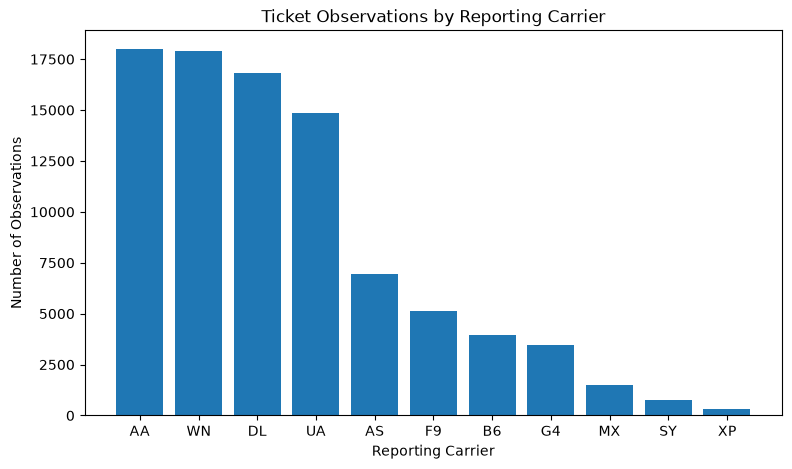

In [26]:
major_carriers = carrier_summary[
    carrier_summary["observations"] >= 100
].copy()

plt.figure(figsize=(9, 5))

plt.bar(
    major_carriers["RpCarrier"],
    major_carriers["observations"]
)

plt.xlabel("Reporting Carrier")
plt.ylabel("Number of Observations")
plt.title("Ticket Observations by Reporting Carrier")

plt.show()

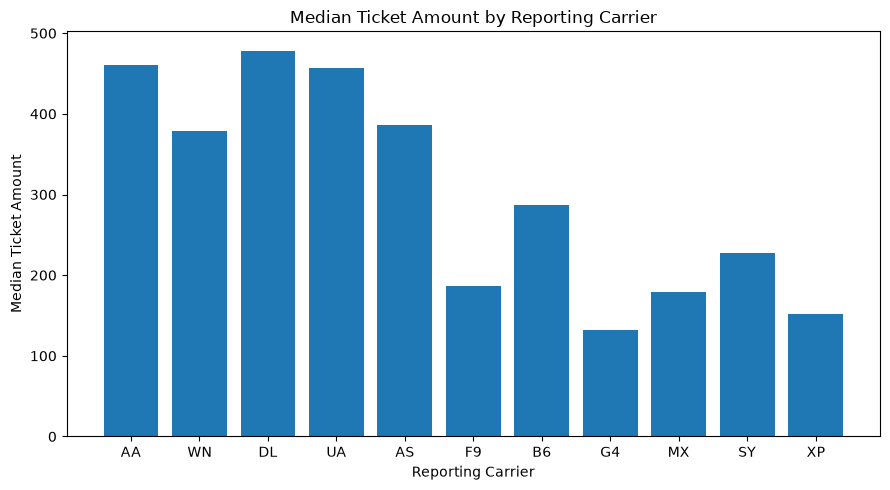

In [27]:
plt.figure(figsize=(9, 5))

plt.bar(
    major_carriers["RpCarrier"],
    major_carriers["median_fare"]
)

plt.xlabel("Reporting Carrier")
plt.ylabel("Median Ticket Amount")
plt.title("Median Ticket Amount by Reporting Carrier")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "02_carrier_median_fare.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Interpretation

The carrier distribution is highly concentrated among a small number of airlines.

The four largest reporting carriers — `AA`, `WN`, `DL`, and `UA` — together account for the majority of observations in the sample. Several smaller carriers contain only a handful of observations, so their raw fare statistics are not sufficiently stable for meaningful comparison.

Among carriers with at least 100 observations, median fares differ substantially.

For example:

- `DL`, `AA`, and `UA` have relatively high median fares of approximately 478, 460, and 456 respectively;
- `WN` and `AS` have intermediate median fares of approximately 379 and 387;
- `F9`, `G4`, `MX`, and `XP` have considerably lower median fares.

This suggests that carrier identity may contain useful explanatory information for ticket prices.

However, these are unconditional comparisons. Differences in carrier-level fares may partly reflect differences in route networks, itinerary distance, trip structure, geography, or purchase characteristics rather than carrier effects alone.

Rare carrier categories are retained in the dataset, but whether they should be combined into an `Other` group will be decided later during model construction rather than during exploratory analysis.

## 6. Geographic Fare Patterns

### 6.1 Origin State

In [28]:
state_summary = (
    df.groupby("OriginState")
    .agg(
        observations=("TotalAmount", "size"),
        mean_fare=("TotalAmount", "mean"),
        median_fare=("TotalAmount", "median")
    )
    .reset_index()
)

state_summary["share_percent"] = (
    state_summary["observations"] / len(df) * 100
)

state_summary = state_summary.sort_values(
    "observations",
    ascending=False
)

display(state_summary.round(2))

,OriginState,observations,mean_fare,median_fare,share_percent
4,CA,12007,486.90,396.20,13.33
8,FL,8549,383.09,295.70,9.49
44,TX,8498,492.05,443.34,9.43
33,NY,4866,435.49,344.80,5.40
13,IL,4141,407.65,354.40,4.60
46,VA,3128,496.28,421.40,3.47
5,CO,3060,450.63,397.40,3.40
9,GA,3028,506.90,428.00,3.36
26,NC,2778,471.66,424.70,3.08
49,WA,2719,470.83,396.79,3.02


In [29]:
state_summary.to_csv(
    OUTPUT_DIR / "02_state_summary.csv",
    index=False
)

For visual clarity, the plots below display only origin states or territories with at least 500 observations. This threshold is used only for presentation; all geographic categories remain in the dataset.

In [30]:
major_states = state_summary[
    state_summary["observations"] >= 500
].copy()

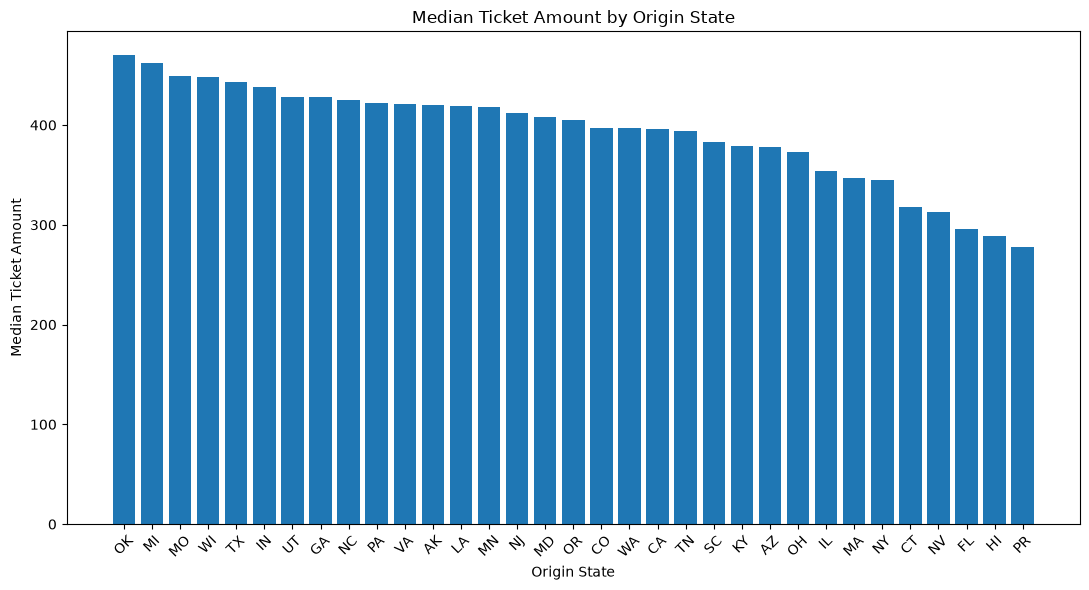

In [31]:
major_states_fare = major_states.sort_values(
    "median_fare",
    ascending=False
)

plt.figure(figsize=(11, 6))

plt.bar(
    major_states_fare["OriginState"],
    major_states_fare["median_fare"]
)

plt.xlabel("Origin State")
plt.ylabel("Median Ticket Amount")
plt.title("Median Ticket Amount by Origin State")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "02_state_median_fare.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

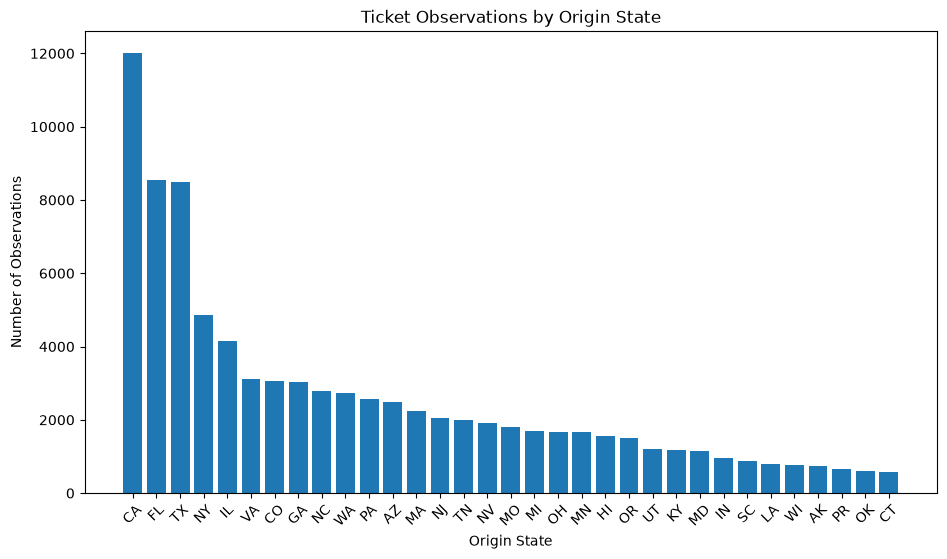

In [32]:
plt.figure(figsize=(11, 6))

plt.bar(
    major_states["OriginState"],
    major_states["observations"]
)

plt.xlabel("Origin State")
plt.ylabel("Number of Observations")
plt.title("Ticket Observations by Origin State")

plt.xticks(rotation=45)

plt.show()

#### Interpretation

Origin-state fare levels vary meaningfully across the sample.

Among states with at least 500 observations, median fares range from roughly the high-200s to the high-400s. For example:

- `OK`, `MI`, `MO`, and `WI` show relatively high median fares;
- `FL`, `PR`, `HI`, and `NV` show relatively low median fares.

The state distribution is also uneven. California, Florida, and Texas account for particularly large shares of the sample, while many states contribute much smaller numbers of observations.

These differences suggest that geographic origin may contain useful explanatory information for fare variation.

However, the observed state-level differences are unconditional. They may reflect differences in route length, carrier mix, itinerary type, or other travel characteristics rather than a pure geographic effect.

`OriginState` therefore remains a reasonable categorical candidate for the broad regression model. Smaller state or territory categories will be handled cautiously during modelling because their coefficient estimates may be less stable.

## 7. Relationships Among Candidate Predictors

The purpose of this section is to identify obvious associations among the explanatory variables before regression modelling begins.

This is a descriptive screening step only. Formal multicollinearity assessment using VIF and regression-based diagnostics will be performed in the initial-model notebook.

### 7.1 Numerical Relationships with Fare and Among Predictors

In [33]:
numeric_candidates = [
    "TotalAmount",
    "TotalDistance",
    "Coupons"
]

numeric_corr = df[numeric_candidates].corr()

display(numeric_corr.round(3))

numeric_corr.to_csv(
    OUTPUT_DIR / "02_numeric_correlations.csv"
)

,TotalAmount,TotalDistance,Coupons
TotalAmount,1.000,0.474,0.407
TotalDistance,0.474,1.000,0.536
Coupons,0.407,0.536,1.000


In [34]:
print(
    f"Correlation between TotalDistance and Coupons: "
    f"{df[['TotalDistance', 'Coupons']].corr().iloc[0,1]:.3f}"
)

Correlation between TotalDistance and Coupons: 0.536


#### Interpretation

`TotalDistance` and `Coupons` are moderately positively correlated:

$$
r = 0.536
$$

This is intuitive because itineraries containing more coupons or flight segments also tend to cover greater total distances.

However, the relationship is not sufficiently strong to conclude that the two variables contain the same information. Each may still capture a different aspect of itinerary structure:

- `TotalDistance` measures the overall travel distance;
- `Coupons` measures itinerary complexity through the number of flight segments.

Both variables also show positive associations with `TotalAmount`, with correlations of 0.474 and 0.407 respectively.

At this exploratory stage, there is therefore no reason to remove either variable. Their joint behaviour will be assessed more formally using VIF and regression results in the initial broad-model notebook.

### 7.2 Round-Trip Status and Number of Coupons

In [35]:
roundtrip_coupon_table = pd.crosstab(
    df["RoundTrip"],
    df["Coupons"],
    normalize="index"
).mul(100)

display(roundtrip_coupon_table.round(2))

roundtrip_coupon_table.to_csv(
    OUTPUT_DIR / "02_roundtrip_coupon_percent.csv"
)

Coupons,1,2,3,4,5,6,7,8,9,10
RoundTrip,,,,,,,,,,
0,69.67,28.49,1.36,0.39,0.07,0.01,0.00,0.0,0.0,0.0
1,0.00,71.69,4.97,21.39,1.43,0.48,0.03,0.0,0.0,0.0


In [36]:
roundtrip_coupon_counts = pd.crosstab(
    df["RoundTrip"],
    df["Coupons"]
)

display(roundtrip_coupon_counts)

Coupons,1,2,3,4,5,6,7,8,9,10
RoundTrip,,,,,,,,,,
0,28271,11559,551,160,29,4,2,2,1,0
1,0,35492,2459,10588,710,239,15,1,1,2


#### Interpretation

`RoundTrip` and `Coupons` are strongly associated in an intuitive way.

For one-way itineraries (`RoundTrip = 0`):

- 69.67% contain 1 coupon;
- 28.49% contain 2 coupons;
- only a very small share contain more than 2 coupons.

For round-trip itineraries (`RoundTrip = 1`):

- 71.69% contain 2 coupons;
- 21.39% contain 4 coupons;
- larger coupon counts also occur more frequently than for one-way itineraries.

This pattern is consistent with itinerary structure: round trips naturally tend to involve more flight segments than one-way trips.

However, the two variables are not interchangeable. `RoundTrip` captures whether the itinerary returns to the origin, while `Coupons` captures the number of individual flight segments.

Both variables will therefore remain as candidate predictors. Their overlap will be assessed formally through VIF and regression results in the next notebook.

## 8. Exploratory Findings

The exploratory analysis reveals several clear patterns in the cleaned June 2026 airline ticket sample.

- `TotalAmount` is positively skewed, with a long upper tail but a well-defined central distribution.
- `TotalDistance` has a moderate positive association with fare, with a correlation of approximately 0.474.
- `Coupons` is also positively associated with fare and reflects itinerary complexity.
- Round-trip tickets have substantially higher fares than one-way tickets.
- `OnLine`, `PurchaseWindowGroup`, and `ItinGeoType` all show meaningful differences in fare distributions across categories.
- Carrier-level fare differences are substantial, although some carrier categories are very small and should be treated cautiously.
- Origin-state fare levels also vary meaningfully across the sample, supporting the use of geography as a potential explanatory factor.
- `TotalDistance` and `Coupons` are moderately correlated, while `RoundTrip` and `Coupons` are structurally related, but none of these variables appears obviously redundant based on exploratory analysis alone.

The exploratory analysis does not identify any of the eight pre-screened candidate predictor blocks as clearly unsuitable or redundant.

All eight candidates are therefore carried forward to the initial broad regression model. Formal assessment of multicollinearity and the incremental contribution of individual predictors will be performed in Notebook 03.

## 9. Pairwise Overview of the Target and Candidate Features

The following 9 × 9 figure summarizes the target and all eight candidate features. Diagonal panels show each variable's distribution as a histogram (numeric variables) or frequency bar chart (categorical variables). Off-diagonal panels show pairwise scatterplots. Categorical values are placed at category positions with slight deterministic jitter so overlapping observations are easier to see. To keep the figure readable and responsive, scatterplots use a reproducible subset of up to 15,000 observations.


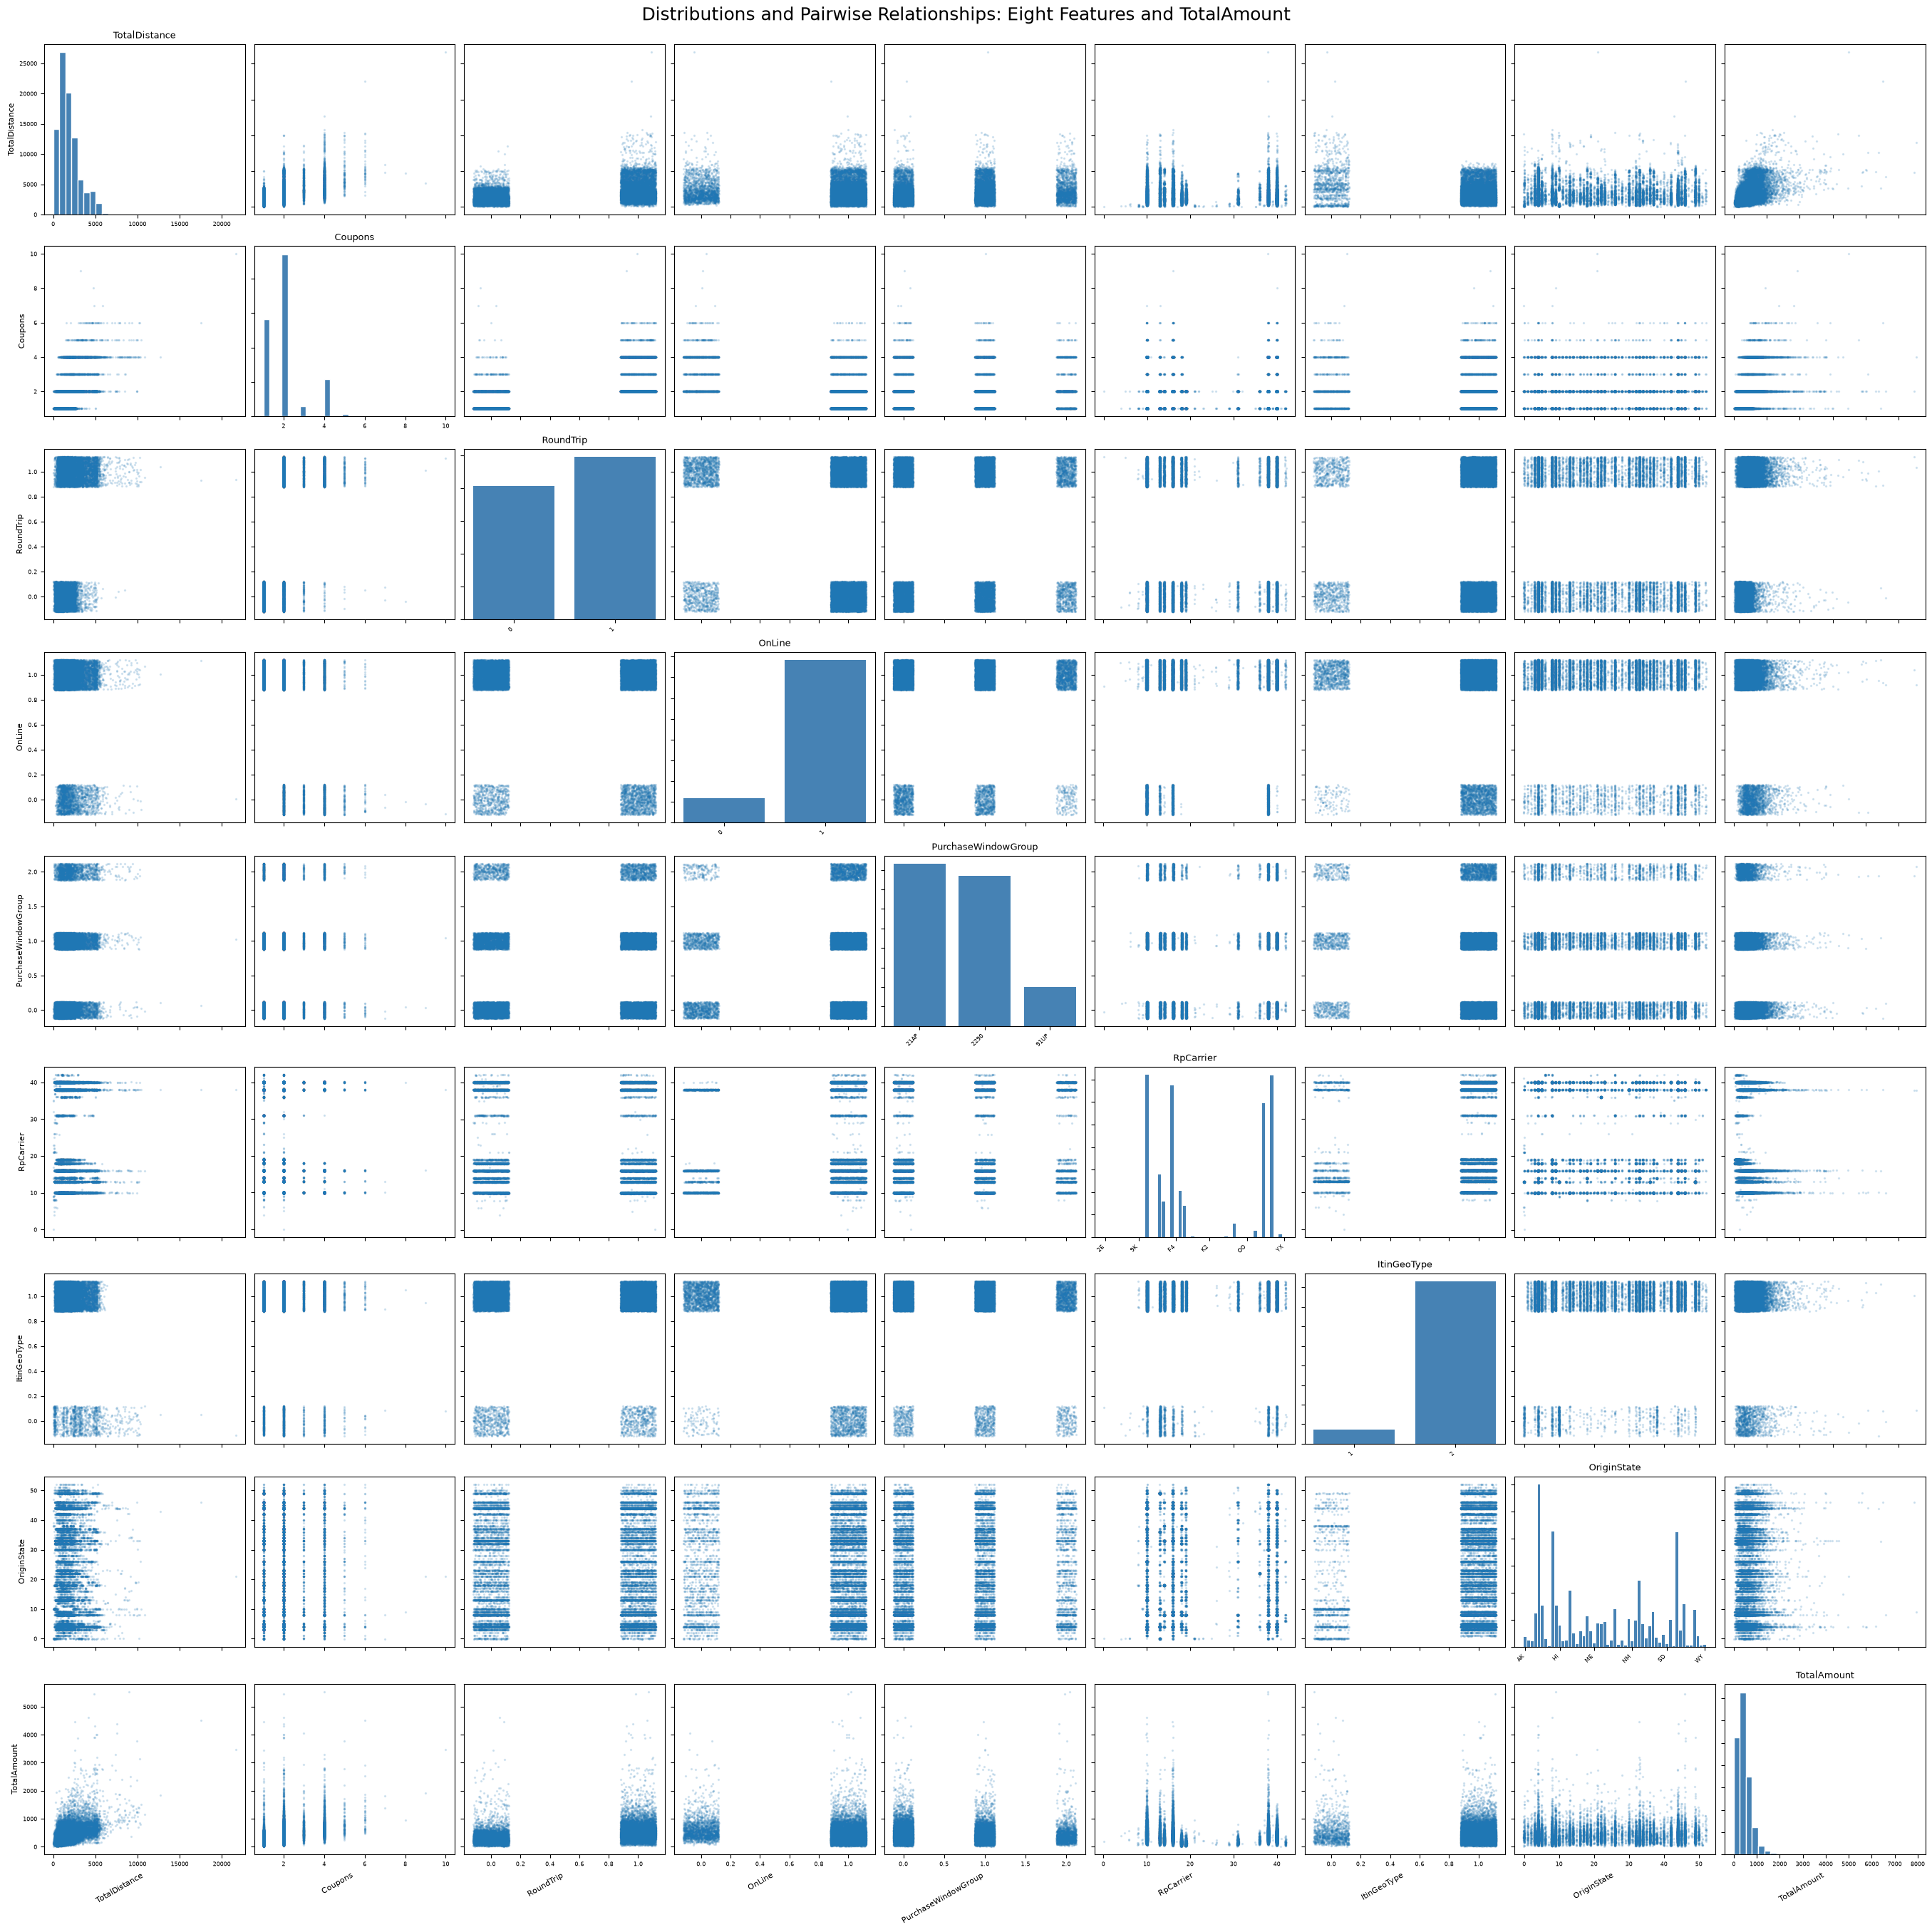

In [3]:
pairwise_variables = [
    "TotalDistance",
    "Coupons",
    "RoundTrip",
    "OnLine",
    "PurchaseWindowGroup",
    "RpCarrier",
    "ItinGeoType",
    "OriginState",
    "TotalAmount",
]

pairwise_data = df[pairwise_variables].copy()
pairwise_numeric = {"TotalDistance", "Coupons", "TotalAmount"}

# Encode categorical variables for the scatterplots while preserving their labels
# for the distribution charts. A fixed seed makes the jitter and point sample repeatable.
pairwise_encoded = pd.DataFrame(index=pairwise_data.index)
pairwise_category_labels = {}
for variable in pairwise_variables:
    if variable in pairwise_numeric:
        pairwise_encoded[variable] = pd.to_numeric(pairwise_data[variable], errors="coerce")
    else:
        categories = pd.Index(pairwise_data[variable].dropna().unique()).sort_values()
        codes = pd.Categorical(pairwise_data[variable], categories=categories).codes
        pairwise_encoded[variable] = np.where(codes >= 0, codes, np.nan)
        pairwise_category_labels[variable] = categories

plot_data = pairwise_encoded.dropna()
max_points = 15_000
if len(plot_data) > max_points:
    plot_data = plot_data.sample(n=max_points, random_state=42)

rng = np.random.default_rng(42)
fig, axes = plt.subplots(
    nrows=len(pairwise_variables),
    ncols=len(pairwise_variables),
    figsize=(27, 27),
    constrained_layout=True
)

for row, y_variable in enumerate(pairwise_variables):
    for col, x_variable in enumerate(pairwise_variables):
        ax = axes[row, col]

        if row == col:
            if y_variable in pairwise_numeric:
                values = pairwise_data[y_variable].dropna()
                ax.hist(values, bins=30, color="steelblue", edgecolor="white")
            else:
                counts = pairwise_data[y_variable].value_counts().reindex(
                    pairwise_category_labels[y_variable], fill_value=0
                )
                ax.bar(np.arange(len(counts)), counts.values, color="steelblue")
                if len(counts) <= 12:
                    ax.set_xticks(np.arange(len(counts)))
                    ax.set_xticklabels(counts.index.astype(str), rotation=45, ha="right", fontsize=6)
                else:
                    ticks = np.unique(np.linspace(0, len(counts) - 1, 6, dtype=int))
                    ax.set_xticks(ticks)
                    ax.set_xticklabels([str(counts.index[i]) for i in ticks], rotation=45, ha="right", fontsize=6)
            ax.set_title(y_variable, fontsize=9)
        else:
            x = plot_data[x_variable].to_numpy(dtype=float).copy()
            y = plot_data[y_variable].to_numpy(dtype=float).copy()
            if x_variable not in pairwise_numeric:
                x += rng.uniform(-0.12, 0.12, size=len(x))
            if y_variable not in pairwise_numeric:
                y += rng.uniform(-0.12, 0.12, size=len(y))
            ax.scatter(x, y, s=2, alpha=0.15, rasterized=True)

        if row == len(pairwise_variables) - 1:
            ax.set_xlabel(x_variable, fontsize=8, rotation=30, ha="right")
        elif row != col:
            ax.set_xticklabels([])
        if col == 0:
            ax.set_ylabel(y_variable, fontsize=8)
        else:
            ax.set_yticklabels([])
        ax.tick_params(axis="both", labelsize=6)

fig.suptitle(
    "Distributions and Pairwise Relationships: Eight Features and TotalAmount",
    fontsize=18
)
fig.savefig(
    OUTPUT_DIR / "02_pairwise_features_target.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
